# 02 · Station Recovery (Sean Qin)

**Question:** Which stations repeatedly have morning net departures, and how often do later net arrivals offset them?

**Plan from the proposal:** compare recovery distributions and full-recovery rates across stations, plot cumulative hourly flows,
and run sensitivity checks with morning deficits of at least five bikes and alternative time windows.

Inputs come from `01_data_cleaning.ipynb`: `station_day.csv` and `station_events.csv`.
Coursebook skills used: `groupby` + named `agg`, `pd.qcut`, `pivot_table`, `cumsum`, `melt`, `merge`, seaborn `histplot` / `lineplot`.

*AI use: this notebook was drafted with help from an AI assistant (Claude) and must be reviewed, rerun, and revised by its owner. Disclose this in the final report, as the course AI policy requires.*

## 0 · Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DATA = Path("../data/processed")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

# Colors: fixed order, same meaning in every notebook
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e5e1", "axes.edgecolor": "#b9b8b2",
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10.5,
    "lines.linewidth": 2,
})

MORNING, LATER = (6, 10), (10, 20)


def recovery_summary(df, by):
    """Recovery summary of morning-deficit station-days for each group in `by`.

    The recovery ratio is unstable when the morning deficit is only 1-2 bikes, so we report three views:
    median ratio, share with full recovery (ratio >= 1), and pooled recovery
    (total later net arrivals / total morning net departures, which weights big deficits more).
    """
    out = df.groupby(by).agg(
        station_days=("recovery", "count"),
        stations=("station_id", "nunique"),
        median_recovery=("recovery", "median"),
        full_recovery_rate=("full_recovery", "mean"),
        later_net=("later_net_arrivals", "sum"),
        morning_net=("morning_net_departures", "sum"),
    )
    out["pooled_recovery"] = out["later_net"] / out["morning_net"]
    return out.drop(columns=["later_net", "morning_net"]).round(3)

In [2]:
station_day = pd.read_csv(DATA / "station_day.csv")
events = pd.read_csv(DATA / "station_events.csv", usecols=["ride_id", "station_id", "event", "day", "hour"])
calendar = station_day.drop_duplicates("day")[["day", "day_type"]]
events = events.merge(calendar, on="day", how="left", validate="many_to_one")

deficit = station_day[station_day["has_morning_deficit"]].copy()
deficit["sample"] = "All deficit station-days"
print(f"{len(station_day):,} active station-days, {len(deficit):,} with a morning deficit")
recovery_summary(deficit, "sample")

30,383 active station-days, 11,408 with a morning deficit


,station_days,stations,median_recovery,full_recovery_rate,pooled_recovery
sample,,,,,
All deficit station-days,11408,1124,0.385,0.376,0.484


Across all 11,408 deficit station-days, the median station gets back about **38%** of its morning loss by 8 p.m., and **38%** fully recover.
Pooled across all bikes, later net arrivals replace about **48%** of morning net departures.

In [3]:
recovery_summary(deficit, "day_type")

,station_days,stations,median_recovery,full_recovery_rate,pooled_recovery
day_type,,,,,
Labor Day,290,290,0.0,0.390,0.230
Weekday,8548,1001,0.5,0.386,0.567
Weekend,2570,832,0.0,0.342,0.102


Weekday deficits recover more than weekend deficits, which fits commuters returning in the evening.
Because recovery behaves differently by day type, **the rest of this notebook uses weekdays only**. Mimi's notebook compares day types directly.

## 1 · Which stations repeatedly lose bikes in the morning?

We count how many of the **21 non-holiday weekdays** each station starts with a deficit.
A **recurring-deficit station** is one with a deficit on **at least 15 of 21 weekdays** (about 70%).

1,523 stations active on weekdays; 264 recurring-deficit stations


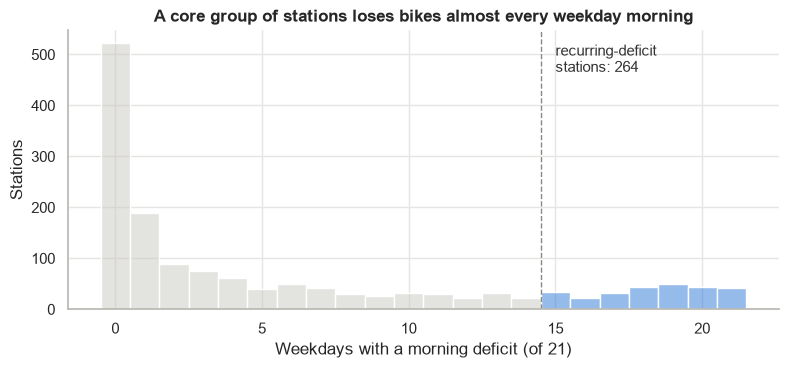

In [4]:
RECURRING_MIN_DAYS = 15
weekday = station_day[station_day["day_type"] == "Weekday"]
n_weekdays = weekday["day"].nunique()

per_station = weekday.groupby(["station_id", "station_name"]).agg(
    weekday_deficit_days=("has_morning_deficit", "sum"),
    mean_morning_net_dep=("morning_net_departures", "mean"),
).reset_index()
per_station["recurring"] = per_station["weekday_deficit_days"] >= RECURRING_MIN_DAYS
recurring_ids = per_station.loc[per_station["recurring"], "station_id"]
print(f"{len(per_station):,} stations active on weekdays; {len(recurring_ids)} recurring-deficit stations")

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(data=per_station, x="weekday_deficit_days", hue="recurring", discrete=True,
             palette={False: "#c9c8c2", True: BLUE}, legend=False, ax=ax)
ax.axvline(RECURRING_MIN_DAYS - 0.5, color=GRAY, ls="--", lw=1)
ax.text(RECURRING_MIN_DAYS, ax.get_ylim()[1] * 0.85, f"recurring-deficit\nstations: {len(recurring_ids)}", color="#333")
ax.set(xlabel=f"Weekdays with a morning deficit (of {n_weekdays})", ylabel="Stations",
       title="A core group of stations loses bikes almost every weekday morning")
fig.tight_layout()
fig.savefig(FIG / "sean_deficit_days_hist.png", dpi=200)
plt.show()

Most stations rarely start the day short, but the bars rise again at the high end: a separate group of stations has a deficit on most weekdays.
This recurring group is where rebalancing attention matters.

## 2 · How often do recurring-deficit stations recover? (supporting table and figure)

In [5]:
rec_days = deficit[deficit["station_id"].isin(recurring_ids) & (deficit["day_type"] == "Weekday")]
station_summary = recovery_summary(rec_days, ["station_id", "station_name"]).reset_index()
station_summary = station_summary.merge(per_station, on=["station_id", "station_name"], how="left", validate="one_to_one")

rec_days = rec_days.copy()
rec_days["sample"] = "Recurring stations, weekdays"
display(recovery_summary(rec_days, "sample"))

cols = ["station_name", "weekday_deficit_days", "mean_morning_net_dep",
        "median_recovery", "full_recovery_rate", "pooled_recovery"]
top_table = station_summary.sort_values("mean_morning_net_dep", ascending=False)[cols].head(15).round(2)
top_table.to_csv(FIG / "sean_top_deficit_stations.csv", index=False)
top_table

,station_days,stations,median_recovery,full_recovery_rate,pooled_recovery
sample,,,,,
"Recurring stations, weekdays",4838,264,0.625,0.394,0.62


,station_name,weekday_deficit_days,mean_morning_net_dep,median_recovery,full_recovery_rate,pooled_recovery
31,Clark St & Elm St,21,16.76,0.80,0.43,0.75
102,Indiana Ave & Roosevelt Rd,20,13.14,0.56,0.30,0.59
87,Clark St & Lincoln Ave,21,11.95,0.62,0.33,0.67
8,Loomis St & Lexington St,21,11.76,0.25,0.05,0.24
116,Clark St & Armitage Ave,21,11.24,0.86,0.48,0.84
196,Federal St & Polk St,20,10.05,0.66,0.45,0.56
159,Wabash Ave & 16th St,20,9.76,0.79,0.35,0.69
108,Clark St & Schiller St,21,9.14,0.77,0.43,0.78
161,Wells St & Polk St,21,8.29,0.85,0.43,0.71
122,Pine Grove Ave & Irving Park Rd,21,8.29,0.44,0.14,0.31


In [6]:
# Do stations with bigger morning losses recover less? Compare by size of the typical deficit.
station_summary["deficit_size"] = pd.qcut(station_summary["mean_morning_net_dep"], 3,
                                          labels=["Smaller deficits", "Middle", "Largest deficits"])
station_summary.groupby("deficit_size", observed=True).agg(
    stations=("station_id", "count"),
    mean_morning_net_dep=("mean_morning_net_dep", "mean"),
    median_full_recovery_rate=("full_recovery_rate", "median"),
    median_pooled_recovery=("pooled_recovery", "median"),
).round(2)

,stations,mean_morning_net_dep,median_full_recovery_rate,median_pooled_recovery
deficit_size,,,,
Smaller deficits,89,1.83,0.42,0.50
Middle,88,3.76,0.42,0.69
Largest deficits,87,6.72,0.38,0.69


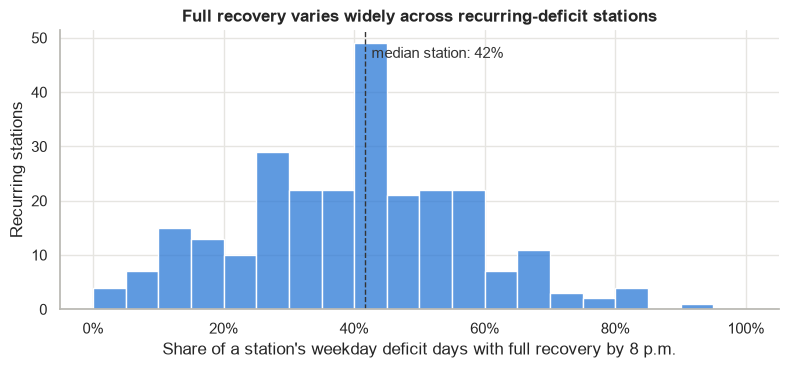

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(data=station_summary, x="full_recovery_rate", bins=np.linspace(0, 1, 21), color=BLUE, edgecolor="white", ax=ax)
med = station_summary["full_recovery_rate"].median()
ax.axvline(med, color="#333", ls="--", lw=1)
ax.text(med + 0.01, ax.get_ylim()[1] * 0.9, f"median station: {med:.0%}", color="#333")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set(xlabel="Share of a station's weekday deficit days with full recovery by 8 p.m.", ylabel="Recurring stations",
       title="Full recovery varies widely across recurring-deficit stations")
fig.tight_layout()
fig.savefig(FIG / "sean_full_recovery_by_station.png", dpi=200)
plt.show()

## 3 · Cumulative hourly flows (main figure)

For each recurring-deficit station we follow the **cumulative net flow** (arrivals − departures) hour by hour from 6 a.m., then average the curve over weekdays.
We split the stations into thirds by full-recovery rate to compare stations that usually recover with ones that rarely do.

Steps: `pivot_table` makes one row per station-day and one column per hour, `cumsum(axis=1)` adds the hours up, and `melt` puts the curves back into long form for `sns.lineplot`.

In [8]:
ev = events[events["station_id"].isin(recurring_ids) & (events["day_type"] == "Weekday") & (events["hour"] >= 6)].copy()
ev["net"] = np.where(ev["event"] == "arrival", 1, -1)

hourly = ev.pivot_table(index=["station_id", "day"], columns="hour", values="net", aggfunc="sum").fillna(0)
cumulative = hourly.cumsum(axis=1)                          # running total since 6 a.m.
station_curves = cumulative.groupby("station_id").mean()    # average weekday curve per station

station_summary["tier"] = pd.qcut(station_summary["full_recovery_rate"], 3,
                                  labels=["Rarely recovers", "Sometimes recovers", "Usually recovers"])
display(station_summary.groupby("tier", observed=True)["full_recovery_rate"].agg(["count", "min", "max"]).round(2))

curves_long = station_curves.reset_index().melt(id_vars="station_id", var_name="hour", value_name="cum_net")
curves_long["hour_end"] = curves_long["hour"].astype(int) + 1   # value at the END of each hour
curves_long = curves_long.merge(station_summary[["station_id", "tier"]], on="station_id", how="left", validate="many_to_one")
curves_long.head()

,count,min,max
tier,,,
Rarely recovers,96,0.00,0.33
Sometimes recovers,80,0.35,0.47
Usually recovers,88,0.47,0.94


,station_id,hour,cum_net,hour_end,tier
0,CHI00005,6,-0.523810,7,Sometimes recovers
1,CHI00214,6,-1.285714,7,Sometimes recovers
2,CHI00217,6,-0.380952,7,Usually recovers
3,CHI00224,6,-0.380952,7,Rarely recovers
4,CHI00227,6,-0.285714,7,Rarely recovers


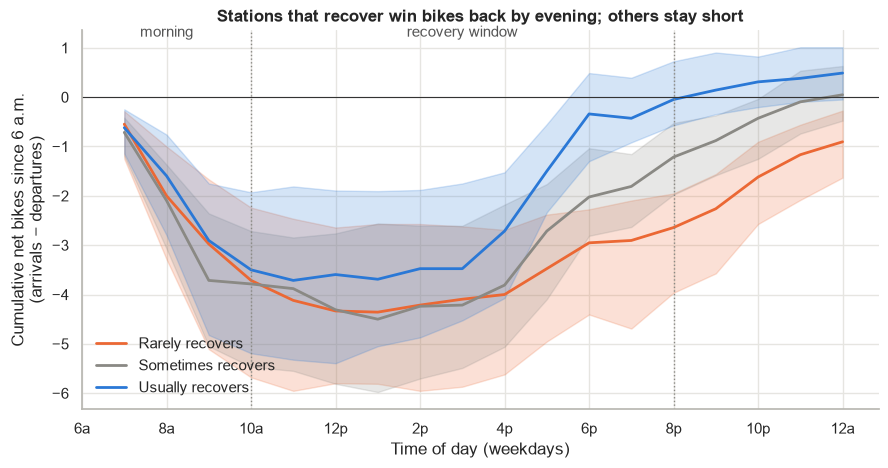

In [9]:
tier_colors = {"Rarely recovers": ORANGE, "Sometimes recovers": GRAY, "Usually recovers": BLUE}
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.lineplot(data=curves_long, x="hour_end", y="cum_net", hue="tier", palette=tier_colors,
             estimator="median", errorbar=("pi", 50), ax=ax)
ax.axhline(0, color="#333", lw=0.8)
for h in (MORNING[1], LATER[1]):
    ax.axvline(h, color=GRAY, ls=":", lw=1)
top = ax.get_ylim()[1]
ax.text(8, top * 0.9, "morning", ha="center", color="#555")
ax.text(15, top * 0.9, "recovery window", ha="center", color="#555")
ax.set_xticks([6, 8, 10, 12, 14, 16, 18, 20, 22, 24], ["6a", "8a", "10a", "12p", "2p", "4p", "6p", "8p", "10p", "12a"])
ax.set(xlabel="Time of day (weekdays)", ylabel="Cumulative net bikes since 6 a.m.\n(arrivals − departures)",
       title="Stations that recover win bikes back by evening; others stay short")
ax.legend(title=None, frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig(FIG / "sean_cumulative_hourly_flow.png", dpi=200)
plt.show()

Each line is the median station in its third; the band is the middle 50% of stations.
All three groups lose bikes at a similar pace from 6 to 10 a.m. They separate afterwards: stations that usually recover climb back toward or above zero by late afternoon, while stations that rarely recover stay below zero through the evening.

## 4 · Sensitivity checks

We recompute the weekday summary under different choices:

1. Count only deficits of **at least 5 bikes**, which avoids unstable ratios like 3 ÷ 1.
2. Use a narrower or wider **morning window** (7–9 a.m., 6–11 a.m.).
3. Extend the **recovery window** to 10 p.m. or midnight.

In [10]:
weekday_events = events[events["day_type"] == "Weekday"]

def flows_for_windows(morning, later):
    e = weekday_events.copy()
    e["window"] = np.select([e["hour"].between(morning[0], morning[1] - 1), e["hour"].between(later[0], later[1] - 1)],
                            ["morning", "later"], default="other")
    e = e[e["window"] != "other"]
    e["flow"] = e["window"] + "_" + e["event"]
    f = e.pivot_table(index=["station_id", "day"], columns="flow", values="ride_id", aggfunc="count").fillna(0)
    f["morning_net_departures"] = f["morning_departure"] - f["morning_arrival"]
    f["later_net_arrivals"] = f["later_arrival"] - f["later_departure"]
    f = f[f["morning_net_departures"] > 0].reset_index()
    f["recovery"] = f["later_net_arrivals"] / f["morning_net_departures"]
    f["full_recovery"] = f["recovery"] >= 1
    return f

specs = {
    "Main (6–10a, 10a–8p)": ((6, 10), (10, 20)),
    "Morning 7–9a": ((7, 9), (9, 20)),
    "Morning 6–11a": ((6, 11), (11, 20)),
    "Recovery to 10p": ((6, 10), (10, 22)),
    "Recovery to midnight": ((6, 10), (10, 24)),
}
pieces = []
for label, (morning, later) in specs.items():
    f = flows_for_windows(morning, later)
    f["windows"] = label
    f["deficit"] = np.where(f["morning_net_departures"] >= 5, "≥ 5 bikes", "1–4 bikes")
    pieces.append(f)
all_specs = pd.concat(pieces, ignore_index=True)

any_deficit = recovery_summary(all_specs, "windows")
any_deficit.insert(0, "deficit", "any (≥ 1)")
big_deficit = recovery_summary(all_specs[all_specs["deficit"] == "≥ 5 bikes"], "windows")
big_deficit.insert(0, "deficit", "≥ 5 bikes")
sensitivity = pd.concat([any_deficit, big_deficit]).reset_index().sort_values(["windows", "deficit"])
sensitivity.to_csv(FIG / "sean_sensitivity.csv", index=False)
sensitivity

,windows,deficit,station_days,stations,median_recovery,full_recovery_rate,pooled_recovery
0,"Main (6–10a, 10a–8p)",any (≥ 1),8548,1001,0.500,0.386,0.567
5,"Main (6–10a, 10a–8p)",≥ 5 bikes,2222,315,0.571,0.282,0.554
1,Morning 6–11a,any (≥ 1),8866,1043,0.500,0.382,0.575
6,Morning 6–11a,≥ 5 bikes,2425,345,0.571,0.281,0.559
2,Morning 7–9a,any (≥ 1),7501,942,0.500,0.431,0.621
7,Morning 7–9a,≥ 5 bikes,1399,260,0.667,0.364,0.645
3,Recovery to 10p,any (≥ 1),8548,1001,0.643,0.428,0.681
8,Recovery to 10p,≥ 5 bikes,2222,315,0.714,0.352,0.676
4,Recovery to midnight,any (≥ 1),8548,1001,0.767,0.468,0.773
9,Recovery to midnight,≥ 5 bikes,2222,315,0.800,0.414,0.762


**How to read this (weekdays only):**

- **Deficits of at least 5 bikes:** the median ratio and pooled recovery barely move, but **full recovery becomes rarer** (about 28% vs 39%). Large losses are seldom completely replaced by 8 p.m.
- **Longer recovery window:** evening returns keep coming after 8 p.m. By midnight, pooled recovery rises to about 77%, but more than half of deficit station-days still have not fully recovered.
- **Morning window:** a narrower 7–9 a.m. window gives somewhat higher recovery and a wider 6–11 a.m. window gives about the same. The main pattern does not depend on the exact cutoff.

## 5 · Preliminary takeaways

1. **264 stations lose bikes on at least 15 of 21 weekday mornings.** Most other stations rarely do.
2. **At these recurring stations, later traffic replaces about 60% of the morning loss** (pooled), but full recovery by 8 p.m. happens on only about 40% of days.
3. **Recovery happens late.** Stations that usually recover regain their bikes mostly between 3 and 6 p.m. (the evening commute); stations that rarely recover are still short at midnight. Those stations are candidates for monitoring.
4. **Stations with bigger typical deficits** fully recover a little less often, but they get back a similar or larger share of their loss.

**Limits:** trip flows cannot show whether a station actually ran empty or was restocked by truck (Divvy's rebalancing is not in the data), and dockless e-bike trips with no station are not counted. These results cover a single month.